# Baseline run: DePlot and UniChart on the validation sample

**Goal:** get a first, untuned score for the pipeline, so later improvements have something to be compared against.

```
chart image -> DePlot (or UniChart) -> table -> LLM + question -> answer -> compare with label
```

| Step | Status |
|---|---|
| Look at the data | done |
| Make a shared stratified validation sample (300 rows) | done |
| Run DePlot on the sample (Kaggle GPU) | done |
| Run UniChart on the same sample (Kaggle GPU) | done |
| LLM answers from the tables | done |
| Scoring (relaxed accuracy) | done |
| Compare the two extractors | done |

## 1. The data

ChartQA, from `datasets/HuggingFaceM4/ChartQA/data/`. Each row is one *question* about a chart.

| Split | Rows | Files |
|---|---|---|
| train | 28,299 | 3 shards of 9,433 |
| validation | 1,920 | 1 |
| test | 2,500 | 1 |

The baseline uses **validation**. The test set is kept for one final run.

In [10]:
import hashlib
from pathlib import Path

import pandas as pd

ROOT = Path.cwd().parent if Path.cwd().name == "data_exploration" else Path.cwd()
VAL = ROOT / "datasets/HuggingFaceM4/ChartQA/data/val-00000-of-00001-0f11003c77497969.parquet"

val = pd.read_parquet(VAL)
chart_id = val["image"].apply(lambda d: hashlib.md5(d["bytes"]).hexdigest())

print("validation rows:", len(val))
print("unique charts:  ", chart_id.nunique(), "(several questions share one chart)")
print()
print(val["human_or_machine"].value_counts().sort_index().to_string())

validation rows: 1920
unique charts:   1055 (several questions share one chart)

human_or_machine
0    960
1    960


## 2. The shared stratified sample

- Made by `utils/make_val_sample.py`, saved as `results/val_sample_300.csv`.
- **Stratified** on `human_or_machine`: the validation set is 50/50, so the sample is 150 + 150.
- Both DePlot and UniChart runs use this exact file, so the two scores can be compared fairly.
- The file stores `row_idx`, the row's position in the validation parquet, so the image can be fetched again.
- Do not re-run the script to make a new sample. Everyone loads the saved CSV.

In [11]:
sample = pd.read_csv(ROOT / "results/val_sample_300.csv")

print("sample rows:    ", len(sample))
print("unique charts:  ", chart_id.iloc[sample["row_idx"]].nunique())
print()
print(sample["human_or_machine"].value_counts().sort_index().to_string())
sample.head()

sample rows:     300
unique charts:   279

human_or_machine
0    150
1    150


,row_idx,query,label,human_or_machine
0,23,IS the value of No more then sum of Yes and Dk?,Yes,0
1,30,What's the value of leftmost bar in the bottom?,12,0
2,39,What is the difference between the longest and...,7,0
3,44,What's the value of United States?,0.124,0
4,59,Find the average of the percentage value of ba...,1.608,0


## 3. Running DePlot on Kaggle

Script: `utils/run_deplot.py`. It reads the sample, runs DePlot once per unique chart, and saves one JSON line per row.
It can be stopped and re-run: rows already in the output file are skipped.

Kaggle setup:
- Private dataset `validation-set` holding the validation parquet, `val_sample_300.csv` and `run_deplot.py`
- Notebook settings: GPU on, Internet on
- A 5-row test first (`--limit 5`), then the full run

Run details:
- GPU used: Kaggle GPU (T4)
- Rows / unique charts: 300 / 279 (DePlot ran once per chart)
- Total DePlot time: about 34 minutes (sum of per-chart times; the whole Kaggle session ran about 38 minutes)
- Seconds per chart: mean 7.27, median 4.63, min 1.06, max 34.94
- Empty tables: 0

## 4. Results

In [12]:
RESULTS = ROOT / "results/deplot_val_300.jsonl"

if RESULTS.exists():
    deplot = pd.read_json(RESULTS, lines=True)
    print("rows:", len(deplot), "| unique charts:", deplot["chart_hash"].nunique())
else:
    deplot = None
    print(f"{RESULTS.name} not found yet. Download it from the Kaggle output and put it in results/.")

rows: 300 | unique charts: 279


In [13]:
if deplot is not None:
    per_chart = deplot.drop_duplicates("chart_hash")["deplot_s"]
    print(f"seconds per chart: mean {per_chart.mean():.2f}, median {per_chart.median():.2f}, max {per_chart.max():.2f}")
    print(f"total GPU time:    {per_chart.sum() / 60:.1f} minutes")
    empty = (deplot["deplot_table"].str.strip() == "").sum()
    print(f"rows with an empty table: {empty}")

seconds per chart: mean 7.27, median 4.63, max 34.94
total GPU time:    33.8 minutes
rows with an empty table: 0


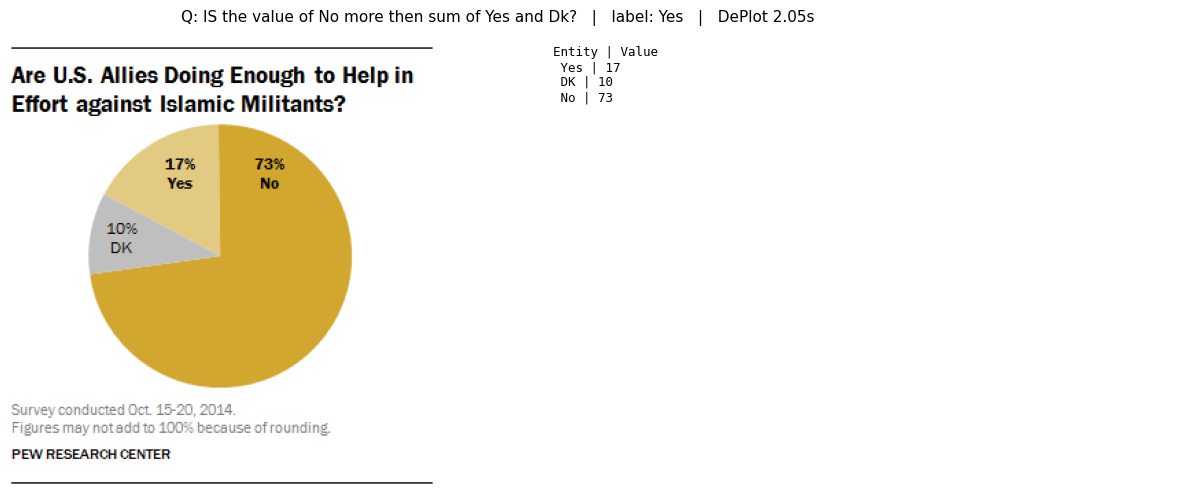

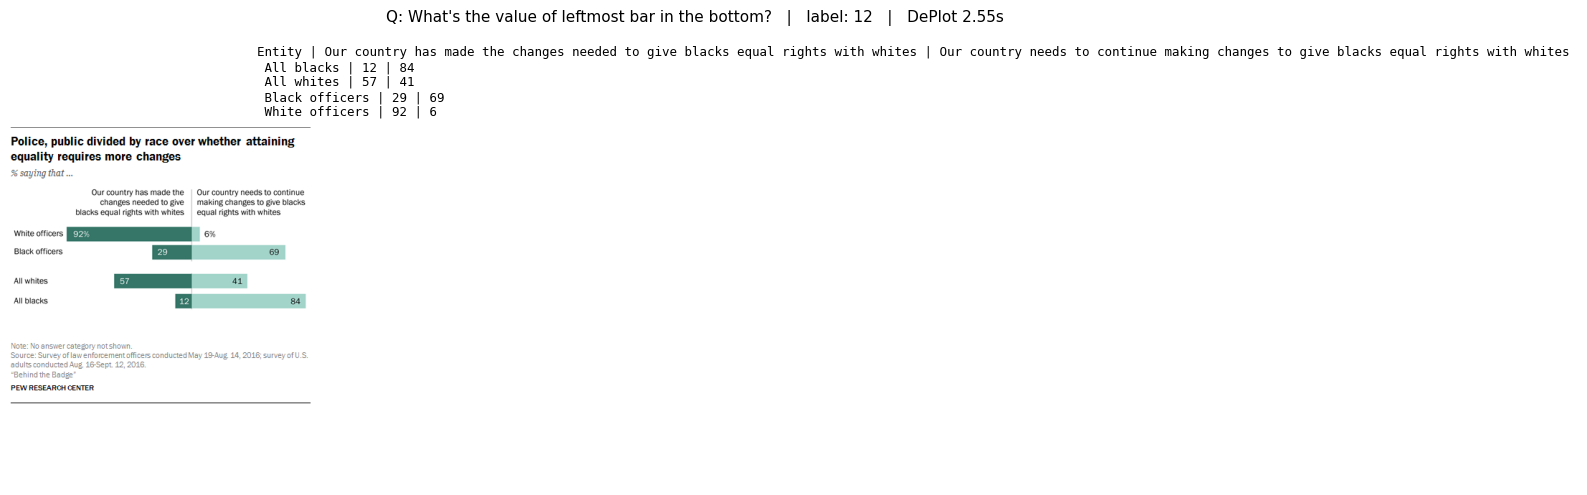

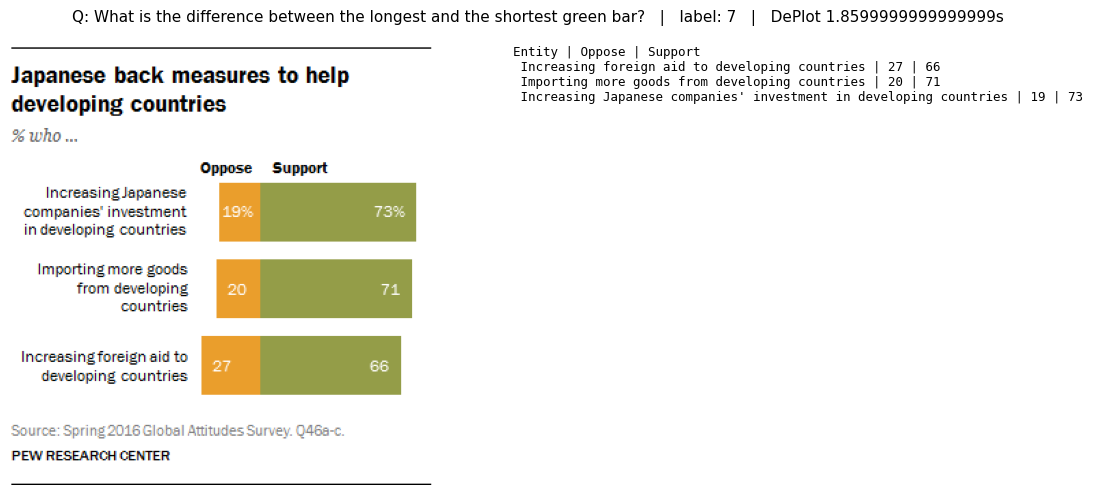

In [14]:
import io

import matplotlib.pyplot as plt
from PIL import Image

N_SHOW = 3  # change to look at more

if deplot is not None:
    for _, r in deplot.head(N_SHOW).iterrows():
        img = Image.open(io.BytesIO(val.iloc[r["row_idx"]]["image"]["bytes"])).convert("RGB")
        fig, (a, b) = plt.subplots(1, 2, figsize=(14, 5), gridspec_kw={"width_ratios": [1.3, 1]})
        a.imshow(img)
        a.axis("off")
        b.text(0, 1, r["deplot_table"], va="top", family="monospace", fontsize=9)
        b.axis("off")
        fig.suptitle(f"Q: {r['query']}   |   label: {r['label']}   |   DePlot {r['deplot_s']}s", fontsize=11)
        plt.tight_layout()
        plt.show()

## 5. Observations

Based on a hand check of 10 charts, not a measured error rate.

- **Good:** simple bar charts with printed values were read correctly. No empty tables.
- **Bad:**
  - Small stacked-bar segments get dropped and the row shifts left.
  - Legend text becomes fake rows.
  - "<1" is read as 1.
  - Values are estimated when no number is printed.
- **Can't answer from a table:** colour and shade questions (6 in the sample, all human-written).
- **Human vs machine:** the human-written group (0) has smaller tables and more zeros (10 vs 2), so expect lower accuracy there.

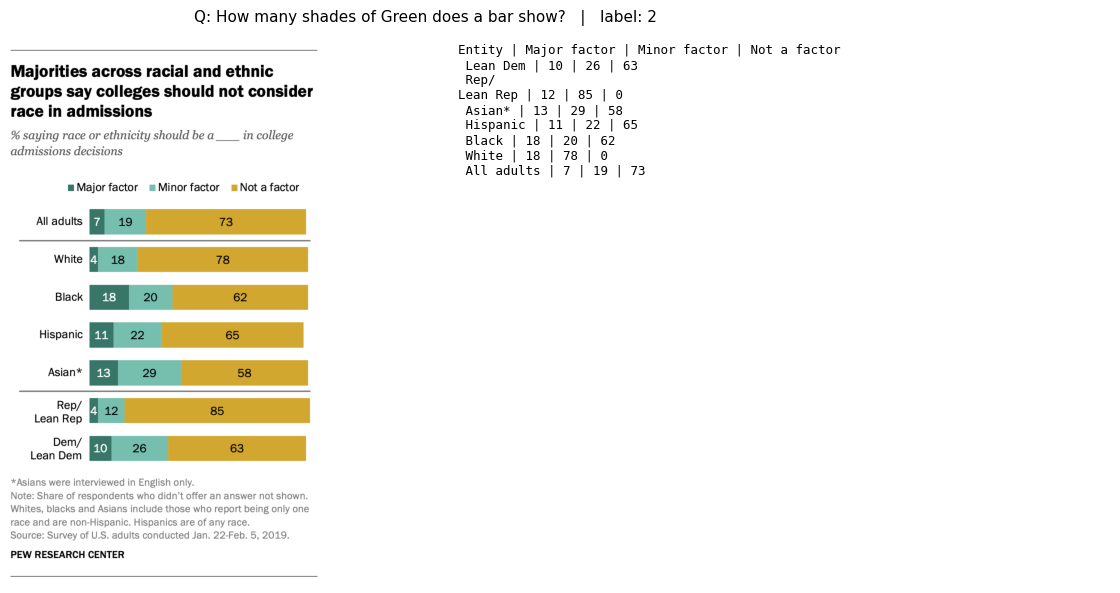

What went wrong: Small segments dropped: White should be 4 | 18 | 78 and Rep/Lean Rep should be 4 | 12 | 85. DePlot lost the first value, shifted the rest left and padded with 0.


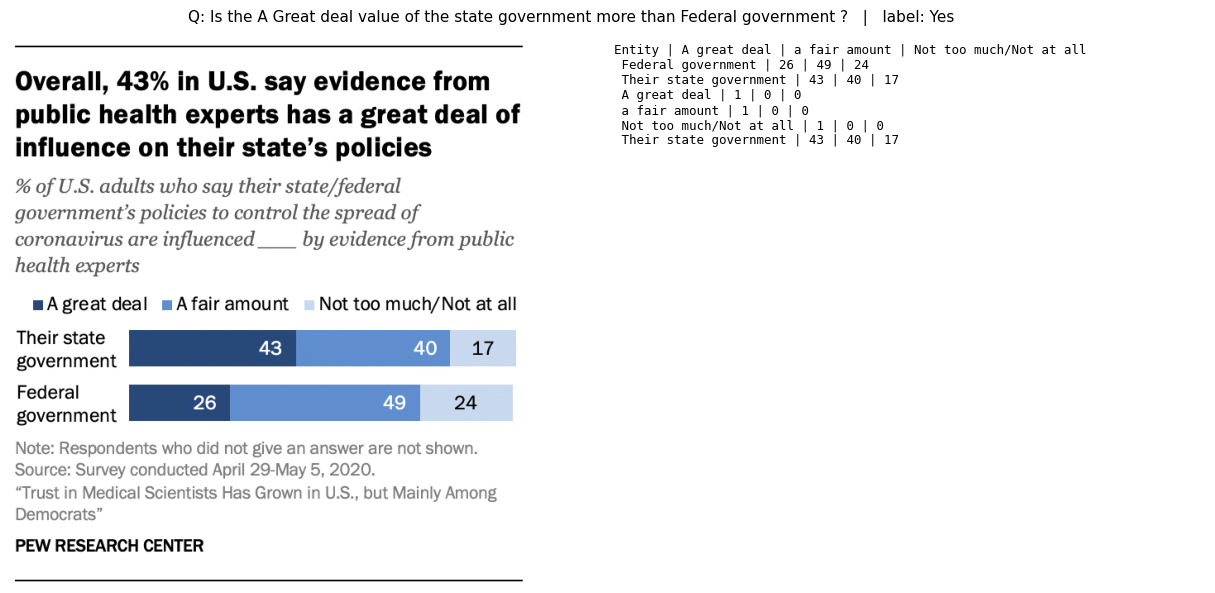

What went wrong: Legend text turned into fake rows ('A great deal | 1 | 0 | 0', ...) and one real row repeated. The real values are right.


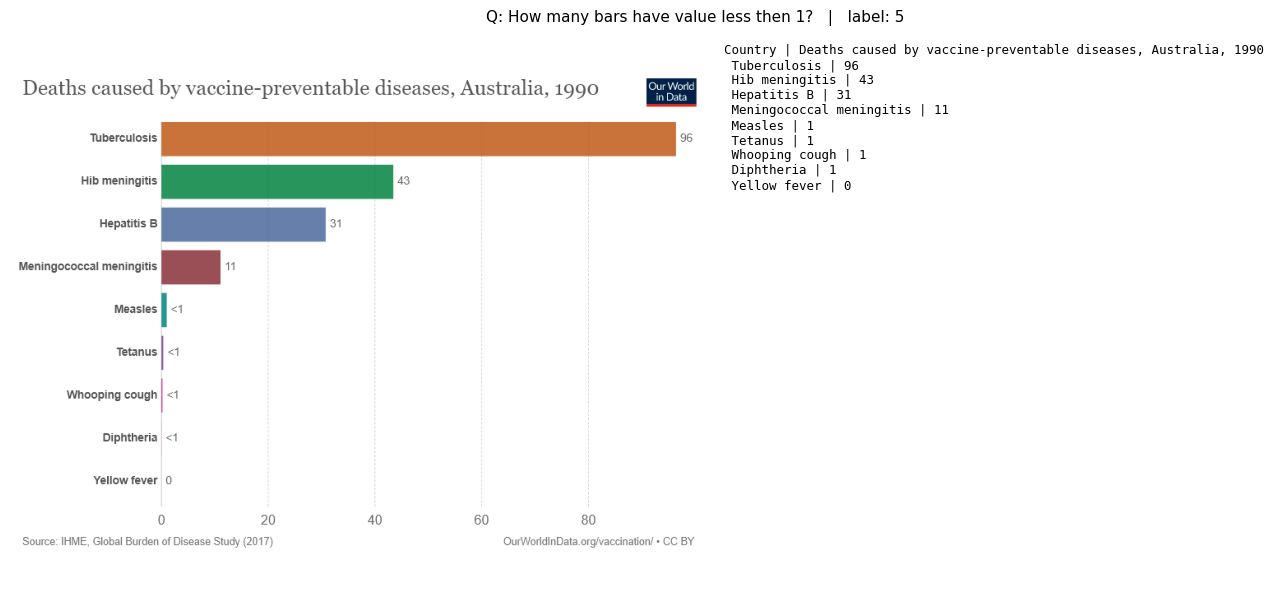

What went wrong: '<1' labels read as 1 (Yellow fever keeps 0). 'How many bars are below 1?' should be 5, but the table has only one value below 1.


In [15]:
FLAWED = {
    323: "Small segments dropped: White should be 4 | 18 | 78 and Rep/Lean Rep should be 4 | 12 | 85. "
         "DePlot lost the first value, shifted the rest left and padded with 0.",
    265: "Legend text turned into fake rows ('A great deal | 1 | 0 | 0', ...) and one real row repeated. "
         "The real values are right.",
    67: "'<1' labels read as 1 (Yellow fever keeps 0). 'How many bars are below 1?' should be 5, "
        "but the table has only one value below 1.",
}


def show_example(row_idx, note):
    r = deplot[deplot["row_idx"] == row_idx].iloc[0]
    img = Image.open(io.BytesIO(val.iloc[row_idx]["image"]["bytes"])).convert("RGB")
    fig, (a, b) = plt.subplots(1, 2, figsize=(14, 6), gridspec_kw={"width_ratios": [1.3, 1]})
    a.imshow(img)
    a.axis("off")
    b.text(0, 1, r["deplot_table"], va="top", family="monospace", fontsize=9)
    b.axis("off")
    fig.suptitle(f"Q: {r['query']}   |   label: {r['label']}", fontsize=11)
    plt.tight_layout()
    plt.show()
    print("What went wrong:", note)


if deplot is not None:
    for idx, note in FLAWED.items():
        show_example(idx, note)

In [16]:
import re

import numpy as np


def count_zero_values(table):
    n = 0
    for line in table.strip().split("\n")[1:]:
        for cell in line.split("|")[1:]:
            digits = re.sub(r"[^\d.\-]", "", cell)
            try:
                n += float(digits) == 0
            except ValueError:
                pass
    return n


def label_in_table(row):
    answer = str(row["label"]).split("|")[0].lower().replace(",", "")
    return answer in row["deplot_table"].lower().replace(",", "")


if deplot is not None:
    stats = deplot.copy()
    stats["n_rows"] = stats["deplot_table"].apply(lambda t: len(t.strip().split("\n")) - 1)
    stats["has_zero"] = stats["deplot_table"].apply(count_zero_values) > 0
    stats["label_in_table"] = stats.apply(label_in_table, axis=1)
    stats["colour_q"] = stats["query"].str.contains(r"colou?r|shade|legend", case=False)

    summary = stats.groupby("human_or_machine").agg(
        questions=("row_idx", "count"),
        avg_table_rows=("n_rows", "mean"),
        tables_with_a_zero=("has_zero", "sum"),
        colour_questions=("colour_q", "sum"),
        label_found_in_table=("label_in_table", "mean"),
    ).round(2)
    print(summary.to_string())
    print()
    print("tables with a zero value:", int(stats["has_zero"].sum()), "of", len(stats))
    print("(label_found_in_table is a rough check only: yes/no and counting answers never appear in a table)")

                  questions  avg_table_rows  tables_with_a_zero  colour_questions  label_found_in_table
human_or_machine                                                                                       
0                       150            5.89                  10                 6                  0.63
1                       150           12.28                   2                 0                  0.91

tables with a zero value: 12 of 300
(label_found_in_table is a rough check only: yes/no and counting answers never appear in a table)


In [17]:
ANSWERS = ROOT / "results/deplot_val_300_answers.jsonl"

if ANSWERS.exists():
    answers = pd.read_json(ANSWERS, lines=True, dtype=False)
    print(f"rows answered: {len(answers)} of {len(deplot)}")
    print(f"accuracy (relaxed): {answers['correct'].mean():.1%}")
    print()
    print(answers.groupby("human_or_machine")["correct"].agg(["mean", "sum", "count"]).round(3).to_string())
else:
    answers = None
    print(f"{ANSWERS.name} not found yet. Run utils/answer_and_score.py first.")

rows answered: 300 of 300
accuracy (relaxed): 81.0%

                  mean  sum  count
human_or_machine                  
0                 0.74  111    150
1                 0.88  132    150


In [18]:
if answers is not None:
    wrong = answers[~answers["correct"]].merge(deplot[["row_idx", "deplot_table"]], on="row_idx")
    for _, r in wrong.head(5).iterrows():
        print(f"row {r['row_idx']} | group {r['human_or_machine']}")
        print("Q:     ", r["query"])
        print("label: ", r["label"], "| LLM answered:", r["answer"])
        print(r["deplot_table"])
        print("-" * 60)

row 30 | group 0
Q:      What's the value of leftmost bar in the bottom?
label:  12 | LLM answered: 92
Entity | Our country has made the changes needed to give blacks equal rights with whites | Our country needs to continue making changes to give blacks equal rights with whites 
 All blacks | 12 | 84 
 All whites | 57 | 41 
 Black officers | 29 | 69 
 White officers | 92 | 6
------------------------------------------------------------
row 39 | group 0
Q:      What is the difference between the longest and the shortest green bar?
label:  7 | LLM answered: 54
Entity | Oppose | Support 
 Increasing foreign aid to developing countries | 27 | 66 
 Importing more goods from developing countries | 20 | 71 
 Increasing Japanese companies' investment in developing countries | 19 | 73
------------------------------------------------------------
row 44 | group 0
Q:      What's the value of United States?
label:  0.124 | LLM answered: 12.4
Country | Share of cumulative plastic exports by top ten e

## 8. Next steps

1. Look at why UniChart loses on human-written questions (smaller tables, fewer columns, colour questions).
2. Sort the wrong answers by cause (done for DePlot in `results/wrong_answers_sorted.csv`) and do the same for UniChart.
3. Decide the next improvement: cleaning the tables, a different extractor, or fine-tuning.
4. Later: fine-tune on train, check on validation, and run the test set once at the end.

In [19]:
from math import comb

runs = {
    "DePlot": ROOT / "results/deplot_val_300_answers.jsonl",
    "UniChart (raw table)": ROOT / "results/unichart_val_300_answers.jsonl",
    "UniChart (rows split)": ROOT / "results/unichart_val_300_answers_clean.jsonl",
}
loaded = {}
for name, path in runs.items():
    if path.exists():
        a = pd.read_json(path, lines=True, dtype=False)
        if len(a) == 300:
            loaded[name] = a

table = []
for name, a in loaded.items():
    g = a.groupby("human_or_machine")["correct"].mean()
    table.append({"extractor": name, "overall": a["correct"].mean(), "human-written (0)": g[0], "machine (1)": g[1]})
comparison = pd.DataFrame(table).set_index("extractor")
print("accuracy, relaxed (%), same 300 rows, same LLM and prompt")
print((comparison * 100).round(1).to_string())


def sign_test(only_a, only_b):
    """Two-sided exact test: if neither extractor were better, the disagreements would split 50/50."""
    n, k = only_a + only_b, max(only_a, only_b)
    return min(1.0, 2 * sum(comb(n, i) for i in range(k, n + 1)) / 2 ** n)


if "DePlot" in loaded and "UniChart (raw table)" in loaded:
    m = loaded["DePlot"][["row_idx", "correct"]].merge(
        loaded["UniChart (raw table)"][["row_idx", "correct"]], on="row_idx", suffixes=("_deplot", "_unichart"))
    print()
    print(pd.crosstab(m["correct_deplot"], m["correct_unichart"], rownames=["DePlot right"], colnames=["UniChart right"]))
    only_dp = int((m["correct_deplot"] & ~m["correct_unichart"]).sum())
    only_uc = int((~m["correct_deplot"] & m["correct_unichart"]).sum())
    print(f"\nright only with DePlot: {only_dp} | right only with UniChart: {only_uc} | "
          f"sign-test p = {sign_test(only_dp, only_uc):.4f}")

accuracy, relaxed (%), same 300 rows, same LLM and prompt
                       overall  human-written (0)  machine (1)
extractor                                                     
DePlot                    81.0               74.0         88.0
UniChart (raw table)      74.0               62.0         86.0
UniChart (rows split)     77.0               65.3         88.7

UniChart right  False  True 
DePlot right                
False              46     11
True               32    211

right only with DePlot: 32 | right only with UniChart: 11 | sign-test p = 0.0019


In [20]:
UNICHART = ROOT / "results/unichart_val_300.jsonl"

if UNICHART.exists() and deplot is not None:
    uc = pd.read_json(UNICHART, lines=True, dtype=False)
    dp_s = deplot.drop_duplicates("chart_hash")["deplot_s"]
    uc_s = uc.drop_duplicates("chart_hash")["unichart_s"]
    print(f"seconds per chart (different GPU sessions): DePlot mean {dp_s.mean():.2f}, UniChart mean {uc_s.mean():.2f}")
    print(f"UniChart tables containing a stray <tag> (a sign of a messy generation): {int(uc['unichart_table'].str.contains(r'<[a-z_]+>').sum())} of {len(uc)}")
    print(f"UniChart tables with ' & ' between rows and no line breaks: {int(uc['unichart_table'].str.contains(' & ').sum())} of {len(uc)}")
    print()
    print("UniChart example:")
    print(uc.loc[1, "unichart_table"])

seconds per chart (different GPU sessions): DePlot mean 7.27, UniChart mean 1.17
UniChart tables containing a stray <tag> (a sign of a messy generation): 24 of 300
UniChart tables with ' & ' between rows and no line breaks: 299 of 300

UniChart example:
Characteristic | Value & White officers | 6% & Black officers | 29% & All whites | 57% & All blacks | 84%


## 6. Next steps

1. Pass each table and its question to an LLM (DeepSeek is already set up in `.env`) and get an answer.
2. Score with ChartQA relaxed accuracy: numbers within 5% of the label, text must match exactly.
3. Compare with the teammate's UniChart results on the same 300 rows.
4. Report accuracy overall and split by `human_or_machine`.
5. Later: fine-tune on train, check on validation, and run the test set once at the end.